# Linear regression, workshop 2 — Walking downhill

Last week the normal equation gave you the best line in one shot. So why does the project then ask
you to build a `GradientDescentOptimizer`?

Because the closed form is a privilege of linear least squares. The moment your model is a logistic
regression, a neural network, or anything where $X^TX$ is too large to invert, there is no formula —
only a cost you can evaluate and a direction you can estimate. Gradient descent is what still works.

The subject gives you a function to practise on:

$$f(x) = 3 + (x - (2\ 6)^T)^T \cdot (x - (2\ 6)^T)$$

A bowl with its minimum at **[2, 6]**, where it takes the value **3**. You know the answer, so any
disagreement is the algorithm's fault.

1. **The gradient** — which way is downhill, computed rather than guessed.
2. **The update rule** — the one line that trains almost every model you will meet.
3. **The optimizer class**, with the history the subject asks you to plot.
4. **Convexity** — why every starting point lands in the same place here.

In [ ]:
# ABOUTME: My Linear Regression workshop 2 - gradient descent on the subject's f.
# ABOUTME: The update rule, the history variable, and the descent path.

import numpy as np
import matplotlib.pyplot as plt

# The data the project subject generates, verbatim. A seed is added so every run of this notebook
# shows the same numbers; the subject does not fix one, so yours will differ in the last decimals.
np.random.seed(42)
X = 4 * np.random.rand(100, 1)
y = 10 + 2 * X + np.random.randn(100, 1)

def ready(*values):
    """True once the exercises a cell depends on have been filled in."""
    return all(v is not None for v in values)

print("X", X.shape, " y", y.shape)
print("generated with intercept 10 and slope 2, plus standard normal noise")

X (100, 1)  y (100, 1)
generated with intercept 10 and slope 2, plus standard normal noise


In [ ]:
TARGET = np.array([2.0, 6.0])      # where the subject's f has its minimum

def f(x):
    """f(x) = 3 + (x - [2, 6])^T (x - [2, 6]). Minimum value 3, reached at [2, 6]."""
    d = np.asarray(x, dtype=float) - TARGET
    return float(3 + d @ d)

def fprime(x):
    """Its gradient: 2(x - [2, 6])."""
    return 2 * (np.asarray(x, dtype=float) - TARGET)

print("f at the minimum:", f(TARGET), "| f at the origin:", f([0.0, 0.0]))

f at the minimum: 3.0 | f at the origin: 43.0


## 1. The gradient

The gradient is the vector of partial derivatives: for each coordinate, *how fast does f change if
I nudge this one?* It points **uphill**, which is why the update subtracts it.

For this f, differentiating gives $f'(x) = 2(x - [2, 6])$ — already written above as `fprime`.

**The habit worth keeping for life:** check an analytic gradient against a numerical one. Nudge a
coordinate by a tiny amount, see how much f moves, divide. A wrong derivative trains silently and
forever, and this catches it in two lines.

In [ ]:
point = np.array([0.5, 1.5])
eps = 1e-6
numerical = np.array([(f(point + eps * e) - f(point - eps * e)) / (2 * eps)
                      for e in np.eye(2)])
print("analytic :", fprime(point))
print("numerical:", numerical.round(6))
print("agree    :", np.allclose(fprime(point), numerical, atol=1e-4))

analytic : [-3. -9.]
numerical: [-3. -9.]
agree    : True


## 2. The update rule

$$\theta \leftarrow \theta - \alpha \, f'(\theta)$$

Subtract the gradient (go downhill), scaled by the **learning rate** $\alpha$ (how big a step).
That is the whole algorithm.

### Exercise 1 — `GradientDescentOptimizer`

The project specifies the class. Two details decide whether it works:

- **`step` must not return anything** — it updates `self.current_` and appends to `self.history_`.
- **Append a copy.** If you write `self.current_ -= ...` (in place) and append `self.current_`,
  every entry of the history is the *same array object*, so your history ends up holding one point
  repeated — and the plot the subject asks for is a single dot. Either rebind
  (`self.current_ = self.current_ - ...`) or append `self.current_.copy()`.

In [ ]:
class GradientDescentOptimizer:
    def __init__(self, f, fprime, start, learning_rate=0.1):
        self.f_ = f
        self.fprime_ = fprime
        self.current_ = np.asarray(start, dtype=float)
        self.learning_rate_ = learning_rate
        self.history_ = [self.current_.copy()]

    def step(self):
        """Take one gradient step. Updates current_, appends to history_, returns nothing."""
        # Rebinding (not -=) means history_ keeps distinct arrays.
        self.current_ = self.current_ - self.learning_rate_ * self.fprime_(self.current_)
        self.history_.append(self.current_.copy())

    def optimize(self, iterations=100):
        """Take `iterations` steps."""
        for _ in range(iterations):
            self.step()

    def getCurrentValue(self):
        return self.current_

    def print_result(self):
        print("Best theta found is " + str(self.current_))
        print("Value of f at this theta: f(theta) = " + str(self.f_(self.current_)))
        print("Value of f prime at this theta: f'(theta) = " + str(self.fprime_(self.current_)))

grad = GradientDescentOptimizer(f, fprime, np.array([0.0, 0.0]), 0.1)
grad.optimize(50)
grad.print_result()

Best theta found is [1.99997146 5.99991437]
Value of f at this theta: f(theta) = 3.000000008148144
Value of f prime at this theta: f'(theta) = [-5.70899077e-05 -1.71269723e-04]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("it reached [2, 6]", lambda: np.allclose(grad.getCurrentValue(), [2.0, 6.0], atol=1e-3))
check("f is back to its minimum of 3", lambda: abs(f(grad.getCurrentValue()) - 3) < 1e-6)
check("the gradient is flat there", lambda: np.allclose(fprime(grad.getCurrentValue()), 0, atol=1e-3))
check("the history has one entry per step, plus the start", lambda: len(grad.history_) == 51)
check("the history holds DISTINCT points (the .copy() trap)",
      lambda: len(np.unique(np.array(grad.history_), axis=0)) > 40)

  it reached [2, 6]: PASS
  f is back to its minimum of 3: PASS
  the gradient is flat there: PASS
  the history has one entry per step, plus the start: PASS
  the history holds DISTINCT points (the .copy() trap): PASS


True

That last check is the one that catches the in-place bug. If it says `not yet` while the others
pass, your maths is right and your history is aliased — every entry is the same object.

**Careful with the subject's own example.** It calls `grad.optimize(10)`. Ten steps at a learning
rate of 0.1 leaves you around **f = 3.4**, not 3 — nothing is broken, you simply have not arrived.
It takes about 25 steps for three decimals and 50 for eight. Do not spend an evening debugging
correct code.

## 3. Plot the history

The subject asks for two plots: f in 3D, and the progression of the gradient using the history.

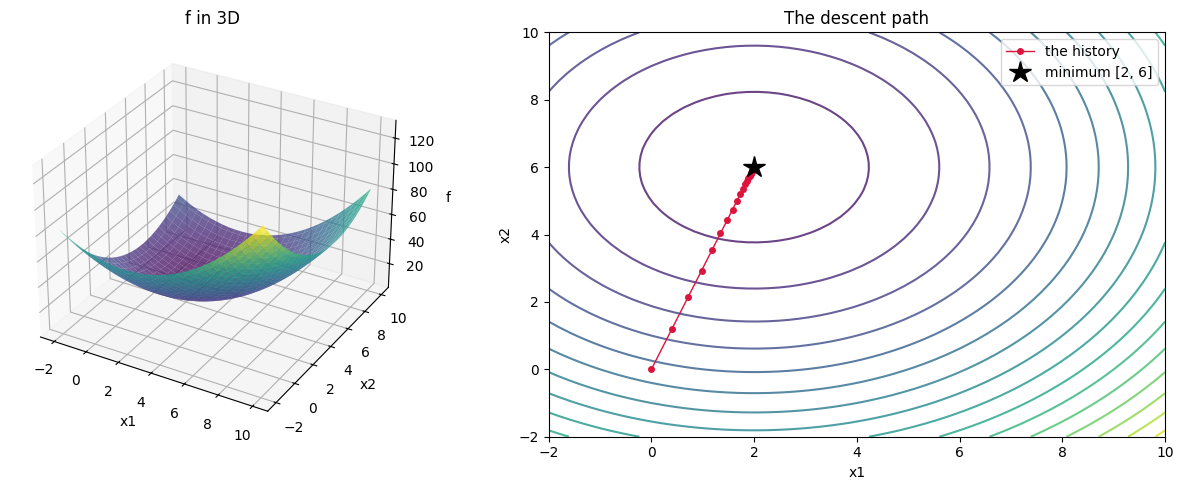

In [ ]:
if not ready(grad.history_) or len(grad.history_) < 2:
    print("Finish exercise 1, then run this cell.")
else:
    path = np.array(grad.history_)
    g = np.linspace(-2, 10, 60)
    A1, A2 = np.meshgrid(g, g)
    Z = 3 + (A1 - 2) ** 2 + (A2 - 6) ** 2

    fig = plt.figure(figsize=(13, 5))
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    ax.plot_surface(A1, A2, Z, cmap="viridis", alpha=0.75, linewidth=0)
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("f"); ax.set_title("f in 3D")

    ax2 = fig.add_subplot(1, 2, 2)
    ax2.contour(A1, A2, Z, levels=20, cmap="viridis", alpha=0.8)
    ax2.plot(path[:, 0], path[:, 1], "o-", color="crimson", ms=4, lw=1, label="the history")
    ax2.plot(2, 6, "k*", ms=16, label="minimum [2, 6]")
    ax2.set_xlabel("x1"); ax2.set_ylabel("x2"); ax2.set_title("The descent path"); ax2.legend()
    plt.tight_layout()

The path runs in a **straight line** to the minimum. That is worth understanding, because the
regression below will not behave this way.

This f is a perfectly round bowl: its curvature is 2 in both directions, so the gradient at any
point aims directly at the centre. When the curvature differs between directions — which is the
normal case — the gradient points *across* the valley instead of along it, and the path zig-zags.

## 4. The same optimizer on the regression

The optimizer takes any `f` and `fprime`. Nothing about it knows what a regression is — so point
it at the MSE and it trains the model from workshop 1.

In [ ]:
X_new = np.hstack([np.ones((X.shape[0], 1)), X])
m = len(X_new)

def mse_cost(theta):
    """The MSE as a function of a flat theta, so the optimizer can use it."""
    pred = X_new.dot(theta.reshape(-1, 1))
    return float(np.mean((pred - y) ** 2))

def mse_grad(theta):
    """Its gradient: 2/m * X^T (X theta - y)."""
    pred = X_new.dot(theta.reshape(-1, 1))
    return (2 / m * X_new.T.dot(pred - y)).ravel()

exact = (np.linalg.pinv(X_new.T.dot(X_new)).dot(X_new.T).dot(y)).ravel()
print("normal equation:", exact.round(4))

normal equation: [10.2151  1.8851]


In [ ]:
reg = GradientDescentOptimizer(mse_cost, mse_grad, np.zeros(2), 0.1)
reg.optimize(1000)
print("gradient descent:", reg.getCurrentValue().round(4))
print("normal equation :", exact.round(4))
print("difference      :", np.abs(reg.getCurrentValue() - exact).round(6))

gradient descent: [10.2151  1.8851]
normal equation : [10.2151  1.8851]
difference      : [0. 0.]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("it ran", lambda: reg is not None)
check("it agrees with the closed form", lambda: np.allclose(reg.getCurrentValue(), exact, atol=1e-2))

  it ran: PASS
  it agrees with the closed form: PASS


True

**The same two numbers**, reached by walking instead of solving. One matrix inversion against a
thousand iterations — which is exactly why you use the closed form when you can, and this when you
cannot.

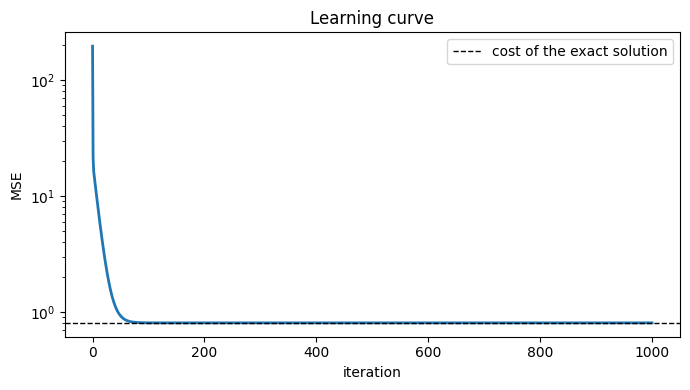

In [ ]:
if not ready(reg):
    print("Finish the exercise above, then run this cell.")
else:
    costs = [mse_cost(p) for p in reg.history_]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(costs, lw=2)
    ax.axhline(mse_cost(exact), color="k", ls="--", lw=1, label="cost of the exact solution")
    ax.set_xlabel("iteration"); ax.set_ylabel("MSE"); ax.set_yscale("log")
    ax.set_title("Learning curve"); ax.legend()
    plt.tight_layout()

Steep, then flat, settling onto the dashed line. **Always plot this on a log scale** — on a linear
axis, "still improving slowly" and "completely stuck" look identical.

### Exercise 3 — convexity

The MSE bowl, like the subject's f, has exactly one bottom. Check it: start from three very
different corners and compare where they end up.

In [ ]:
starts = [np.array([-30.0, 6.0]), np.array([60.0, -1.0]), np.array([0.0, 0.0])]

endings = []
for s in starts:
    opt = GradientDescentOptimizer(mse_cost, mse_grad, s, 0.1)
    opt.optimize(2000)
    endings.append(opt.getCurrentValue())

for s, e in zip(starts, endings):
    print(f"from {s} -> {np.round(e, 3)}")
print("exact solution    ->", exact.round(3))

from [-30.   6.] -> [10.215  1.885]
from [60. -1.] -> [10.215  1.885]
from [0. 0.] -> [10.215  1.885]
exact solution    -> [10.215  1.885]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("three runs", lambda: len(endings) == 3)
check("all three agree", lambda: np.allclose(endings[0], endings[1], atol=0.05)
                                 and np.allclose(endings[1], endings[2], atol=0.05))
check("and they match the closed form", lambda: np.allclose(endings[0], exact, atol=0.05))

  three runs: PASS
  all three agree: PASS
  and they match the closed form: PASS


True

Same destination every time. That is **convexity**, and it is a property of this cost function, not
a general law: train a neural network from three different starting points and you get three
different models. Enjoy it while it lasts.

## What to take away

1. **The gradient is computed, not guessed** — and checked against a numerical derivative.
2. **`step` returns nothing and appends a copy.** The in-place bug turns the required history plot
   into a single dot.
3. **Ten iterations is not convergence.** The subject's own example lands at f ≈ 3.4; that is the
   budget, not a bug.
4. **The optimizer is generic.** Point it at the MSE and it trains your regression — same answer as
   the normal equation, a thousand times the work.
5. **A round bowl gives a straight path.** Unequal curvature gives a zig-zag, which is next week.
6. **Plot the learning curve on a log scale**, every run.
7. **Convex means one bottom**, so any start works. Only this kind of problem is that kind.

### Take it home
The subject asks you to tweak the learning rate and the number of iterations and report what
happens. Keep your `history_` plots — that is next workshop, and you will already have the data.